# Part II · Notebook 04 — X4: repairing minority representation, and what it costs

Part I found that TVAE almost erased non-white individuals in Adult and women in German Credit, while DDPM and CTGAN
inflated some groups. We test two repairs that any practitioner can apply to any generator:

* **Stratified release** — generate a pool 20× the target size (10× for DDPM) and subsample it so the protected group's share equals
  its training share (rejection sampling; no retraining).
* **Per-group generation** — fit one generator per protected group and sample each group in proportion.

For each we measure representation, the outcome gap between groups, utility (overall and per group) and membership risk
**separately for protected-group records**, because per-group models are trained on fewer records and may memorise them.
Hypotheses H11 and H12 are tested in Notebook 05.

In [1]:
import os, time, json, gc, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import sdaudit as sa
QUICK = os.environ.get("QUICK", "0") == "1"
if QUICK: sa.CFG.update(ctgan_epochs=3, tvae_epochs=3, ddpm_steps=50)
OUT = "outputs2"; os.makedirs(f"{OUT}/tables", exist_ok=True); os.makedirs(f"{OUT}/figures", exist_ok=True)
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1); plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
T0 = time.time()
CASES = [("adult", "race"), ("german", "sex"), ("compas", "race")]
SEEDS = [0, 1, 2] if not QUICK else [0]
GENS = ["TVAE", "CTGAN", "DDPM", "CART"]
if QUICK: CASES = CASES[1:2]; GENS = ["TVAE", "CART"]

In [2]:
rows = []
for key, attr in CASES:
    df, meta = sa.load(key)
    for seed in SEEDS:
        tr, ho, te = sa.make_split(df, meta, seed)
        u_r, p_r = sa.utility(tr, te, meta, seed); real = (u_r, sa.fairness(tr, te, p_r["HGB"], meta))
        for g in GENS:
            fn = sa.GENERATORS[g]; mult = 10 if g == "DDPM" else 20
            t0 = time.time(); pool = sa.postprocess(fn(tr, meta, seed, n=len(tr) * mult), tr, meta)   # one fit; plain = a random n-subset of the pool
            print(f"   pool of {len(pool)} from {g}: {time.time()-t0:.0f}s", flush=True)
            variants = {"plain": lambda: pool.sample(len(tr), random_state=seed).reset_index(drop=True),
                        "stratified": lambda: sa.stratify_pool(pool, tr, meta, seed, attr),
                        "per-group": lambda: sa.per_group_release(fn, tr, meta, seed, attr)}
            for vname, make in variants.items():
                t0 = time.time(); syn = make(); short = syn.attrs.get("shortfall", 0)
                r, _ = sa.evaluate_release(tr, ho, te, syn, meta, seed, real=real, anonymeter_on=False, group_attr=attr)
                r.update(dataset=meta["name"], attr=attr, seed=seed, generator=g, variant=vname, shortfall=short,
                         repr_ratio=r[f"{attr}|share"] / r[f"{attr}|share_real"], gap_err=abs(r[f"{attr}|base_gap"] - r[f"{attr}|base_gap_real"]),
                         auc_prot=r[f"{attr}|auc_unpriv"], auc_ref=r[f"{attr}|auc_priv"],
                         auc_prot_real=r[f"{attr}|auc_unpriv_real"], auc_ref_real=r[f"{attr}|auc_priv_real"])
                rows.append(r); pd.DataFrame(rows).to_csv(f"{OUT}/tables/X4_representation.csv", index=False); gc.collect()
                print(f"{meta['name']:<7} s{seed} {g:<6} {vname:<10} repr={r['repr_ratio']:.2f} gapErr={r['gap_err']:.3f} U={r['util_ratio']:.3f} "
                      f"AUCprot={r['auc_prot']:.3f} MIAprot={r.get('mia_auc_protected', np.nan):.3f} MIAref={r.get('mia_auc_reference', np.nan):.3f} | {time.time()-t0:.0f}s", flush=True)
X4 = pd.DataFrame(rows)

   pool of 100000 from TVAE: 40s


Adult   s0 TVAE   plain      repr=0.04 gapErr=0.145 U=0.952 AUCprot=0.908 MIAprot=0.521 MIAref=0.513 | 8s


Adult   s0 TVAE   stratified repr=0.99 gapErr=0.028 U=0.955 AUCprot=0.908 MIAprot=0.519 MIAref=0.510 | 8s


Adult   s0 TVAE   per-group  repr=1.00 gapErr=0.209 U=0.933 AUCprot=0.870 MIAprot=0.518 MIAref=0.509 | 43s


   pool of 100000 from CTGAN: 155s


Adult   s0 CTGAN  plain      repr=2.31 gapErr=0.094 U=0.943 AUCprot=0.909 MIAprot=0.525 MIAref=0.512 | 9s


... (134 outputs left out)

   pool of 49360 from CART: 1s


COMPAS  s2 CART   plain      repr=1.01 gapErr=0.032 U=0.989 AUCprot=0.719 MIAprot=0.590 MIAref=0.600 | 3s


COMPAS  s2 CART   stratified repr=1.00 gapErr=0.026 U=0.993 AUCprot=0.736 MIAprot=0.592 MIAref=0.608 | 3s


COMPAS  s2 CART   per-group  repr=1.00 gapErr=0.014 U=1.005 AUCprot=0.725 MIAprot=0.593 MIAref=0.609 | 3s


In [3]:
X4["in_band"] = X4.repr_ratio.between(0.8, 1.25)
summ = X4.groupby(["dataset", "generator", "variant"], sort=False).agg(repr_ratio=("repr_ratio", "mean"), in_band=("in_band", "mean"), gap_err=("gap_err", "mean"),
        util=("util_ratio", "mean"), auc_prot=("auc_prot", "mean"), mia_prot=("mia_auc_protected", "mean"), mia_ref=("mia_auc_reference", "mean"),
        mia_all=("mia_auc_max", "mean"), shortfall=("shortfall", "mean"))
summ.to_csv(f"{OUT}/tables/X4_summary.csv"); display(summ.round(3))

repr_ratio  in_band  gap_err   util  auc_prot  \
dataset generator variant                                                     
Adult   TVAE      plain            0.053    0.000    0.118  0.960     0.904   
                  stratified       0.952    1.000    0.059  0.960     0.898   
                  per-group        1.000    1.000    0.168  0.946     0.890   
        CTGAN     plain            1.699    0.333    0.082  0.942     0.883   
                  stratified       1.000    1.000    0.095  0.939     0.879   
                  per-group        1.000    1.000    0.037  0.934     0.806   
        DDPM      plain            1.441    0.333    0.071  0.934     0.859   
                  stratified       1.000    1.000    0.062  0.936     0.857   
                  per-group        1.000    1.000    0.051  0.926     0.869   
        CART      plain            0.987    1.000    0.031  0.985     0.907   
                  stratified       1.000    1.000    0.015  0.986     0.915   
                  per-group        1.000    1.000    0.010  0.984     0.907   
German  TVAE      plain            0.220    0.000    0.103  0.781     0.594   
                  stratified       1.000    1.000    0.095  0.771     0.650   
                  per-group        1.000    1.000    0.050  0.874     0.625   
        CTGAN     plain            1.083    0.667    0.065  0.643     0.570   
                  stratified       1.000    1.000    0.122  0.638     0.454   
                  per-group        1.000    1.000    0.065  0.583     0.440   
        DDPM      plain            2.244    0.000    0.508  0.881     0.623   
                  stratified       1.000    1.000    0.525  0.914     0.638   
                  per-group        1.000    1.000    0.205  0.831     0.556   
        CART      plain            0.901    0.667    0.037  0.952     0.675   
                  stratified       1.000    1.000    0.036  0.939     0.666   
                  per-group        1.000    1.000    0.096  0.946     0.702   
COMPAS  TVAE      plain            1.417    0.000    0.392  0.956     0.696   
                  stratified       1.000    1.000    0.390  0.947     0.682   
                  per-group        1.000    1.000    0.161  0.954     0.664   
        CTGAN     plain            0.948    0.667    0.075  0.835     0.553   
                  stratified       1.000    1.000    0.079  0.863     0.607   
                  per-group        1.000    1.000    0.052  0.743     0.514   
        DDPM      plain            1.026    1.000    0.018  0.994     0.713   
                  stratified       1.000    1.000    0.013  0.998     0.727   
                  per-group        1.000    1.000    0.011  1.003     0.728   
        CART      plain            0.991    1.000    0.018  0.991     0.711   
                  stratified       1.000    1.000    0.010  0.985     0.704   
                  per-group        1.000    1.000    0.013  0.995     0.703   

                              mia_prot  mia_ref  mia_all  shortfall  
dataset generator variant                                            
Adult   TVAE      plain          0.515    0.516    0.516        0.0  
                  stratified     0.508    0.514    0.514       33.0  
                  per-group      0.499    0.514    0.512        0.0  
        CTGAN     plain          0.510    0.512    0.510        0.0  
                  stratified     0.515    0.512    0.510        0.0  
                  per-group      0.511    0.509    0.508        0.0  
        DDPM      plain          0.533    0.511    0.510        0.0  
                  stratified     0.527    0.510    0.509        0.0  
                  per-group      0.535    0.513    0.513        0.0  
        CART      plain          0.595    0.593    0.593        0.0  
                  stratified     0.607    0.596    0.598        0.0  
                  per-group      0.598    0.596    0.596        0.0  
German  TVAE      plain          0.482    0.544

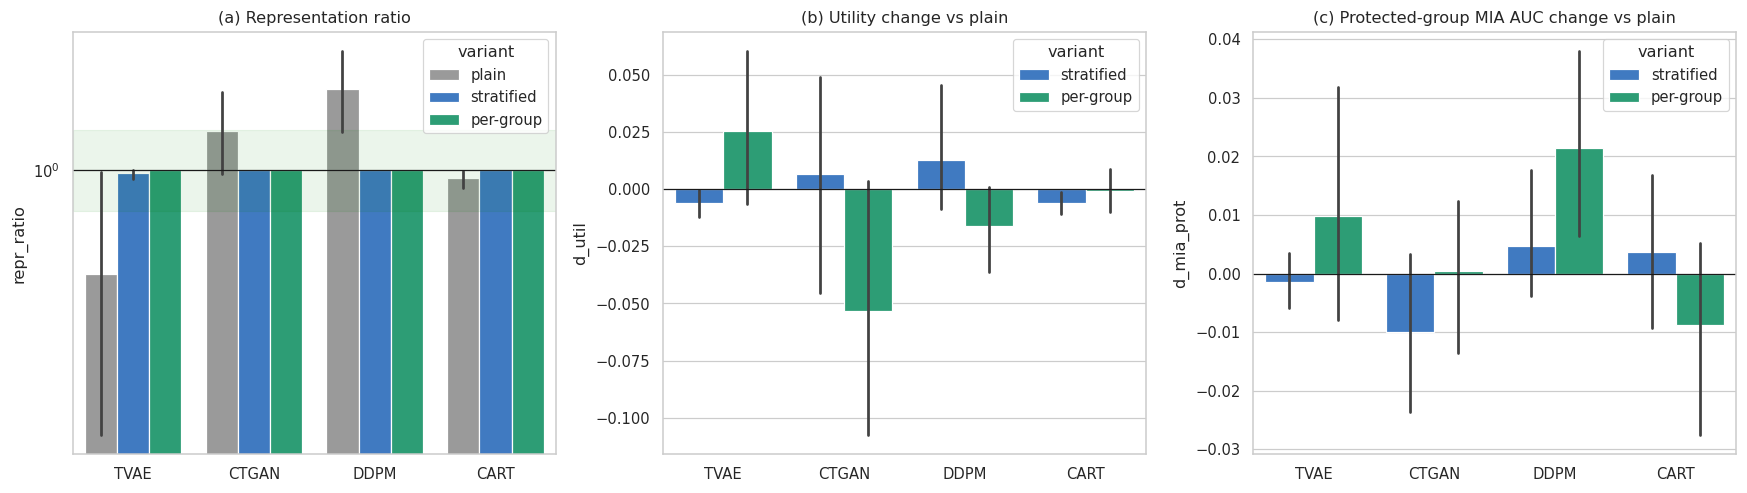

Notebook runtime: 93.1 min


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
order = ["plain", "stratified", "per-group"]
sns.barplot(data=X4, x="generator", y="repr_ratio", hue="variant", hue_order=order, ax=axes[0], errorbar=("ci", 95), palette=["#9a9a9a", "#2a78d6", "#1baf7a"])
axes[0].axhspan(0.8, 1.25, color="green", alpha=0.08); axes[0].axhline(1, c="k", lw=0.8); axes[0].set_yscale("log"); axes[0].set_title("(a) Representation ratio"); axes[0].set_xlabel("")
d = X4.merge(X4[X4.variant == "plain"][["dataset", "seed", "generator", "util_ratio", "mia_auc_protected"]], on=["dataset", "seed", "generator"], suffixes=("", "_plain"))
d["d_util"] = d.util_ratio - d.util_ratio_plain; d["d_mia_prot"] = d.mia_auc_protected - d.mia_auc_protected_plain
sns.barplot(data=d[d.variant != "plain"], x="generator", y="d_util", hue="variant", ax=axes[1], errorbar=("ci", 95), palette=["#2a78d6", "#1baf7a"])
axes[1].axhline(0, c="k", lw=0.8); axes[1].set_title("(b) Utility change vs plain"); axes[1].set_xlabel("")
sns.barplot(data=d[d.variant != "plain"], x="generator", y="d_mia_prot", hue="variant", ax=axes[2], errorbar=("ci", 95), palette=["#2a78d6", "#1baf7a"])
axes[2].axhline(0, c="k", lw=0.8); axes[2].set_title("(c) Protected-group MIA AUC change vs plain"); axes[2].set_xlabel("")
plt.tight_layout(); fig.savefig(f"{OUT}/figures/X4_representation.png"); plt.show()
d.to_csv(f"{OUT}/tables/X4_deltas.csv", index=False)
print(f"Notebook runtime: {(time.time()-T0)/60:.1f} min")